# Exploring and Predicting Airline Passenger Satisfaction

We will explore passenger experiences and later compare models that predict whether passengers are satisfied or neutral/dissatisfied.

Dataset: [Airline Passenger Satisfaction on Kaggle](https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction)

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


## Load and combine the data

Both files contain satisfaction labels, so we can combine them for exploration. The first CSV column is a saved row index, which we exclude when loading. We keep the original dataframes so the supplied train/test split remains available.

When we start modeling, we will use a separate evaluation set and fit preprocessing only on the training data. The passenger `id` is an identifier, so it should not be used to predict satisfaction.

In [2]:
data_dir = Path("dataset")

train_df = pd.read_csv(data_dir / "train.csv", index_col=0)
test_df = pd.read_csv(data_dir / "test.csv", index_col=0)

df = pd.concat([train_df, test_df], ignore_index=True)

print(f"Training records: {len(train_df):,}")
print(f"Test records: {len(test_df):,}")
print(f"Combined dataframe: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied
3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied


Training records: 103,904
Test records: 25,976
Combined dataframe: 129,880 rows, 24 columns


## Exploring passenger satisfaction

Each percentage is the share of passengers in that group labeled **satisfied**. For example, 40% means 40 out of every 100 passengers were satisfied; the remaining 60% were neutral or dissatisfied. This measures how many passengers are satisfied, rather than the intensity of their satisfaction.


### 1. Satisfaction by class and travel purpose
Compare business and personal travel within each class. The labels show each group's satisfaction percentage and passenger count.

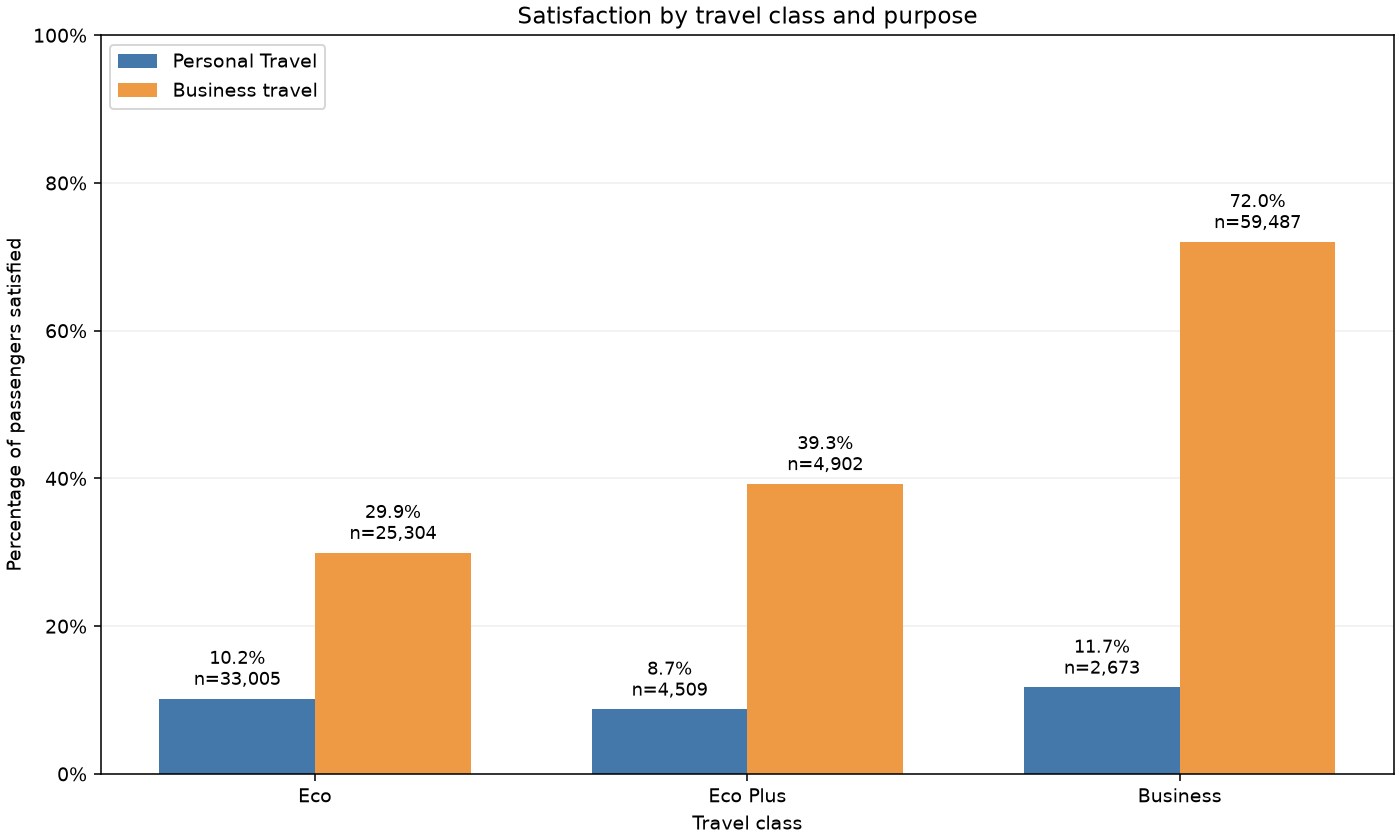

In [3]:
satisfied = df["satisfaction"].eq("satisfied")
class_order = ["Eco", "Eco Plus", "Business"]
travel_order = ["Personal Travel", "Business travel"]
class_summary = (
    df.assign(is_satisfied=satisfied)
    .groupby(["Class", "Type of Travel"])["is_satisfied"]
    .agg(rate="mean", count="size")
)

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
colors = ["#4477AA", "#EE9944"]
for i, travel in enumerate(travel_order):
    group = class_summary.xs(travel, level="Type of Travel").reindex(class_order)
    positions = [x + (i - 0.5) * 0.36 for x in range(len(class_order))]
    bars = ax.bar(positions, group["rate"] * 100, width=0.36,
                  label=travel, color=colors[i])
    labels = [f"{rate:.1%}\nn={count:,}" for rate, count in zip(group["rate"], group["count"])]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=9)
ax.set_xticks(range(len(class_order)), class_order)
ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 20))
ax.set_ylabel("Percentage of passengers satisfied")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlabel("Travel class")
ax.set_title("Satisfaction by travel class and purpose")
ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.show()


### 2. Arrival delay and satisfaction
Missing arrival delays are shown separately. The delay ranges use the recorded minutes; we do not fill missing values with zero.

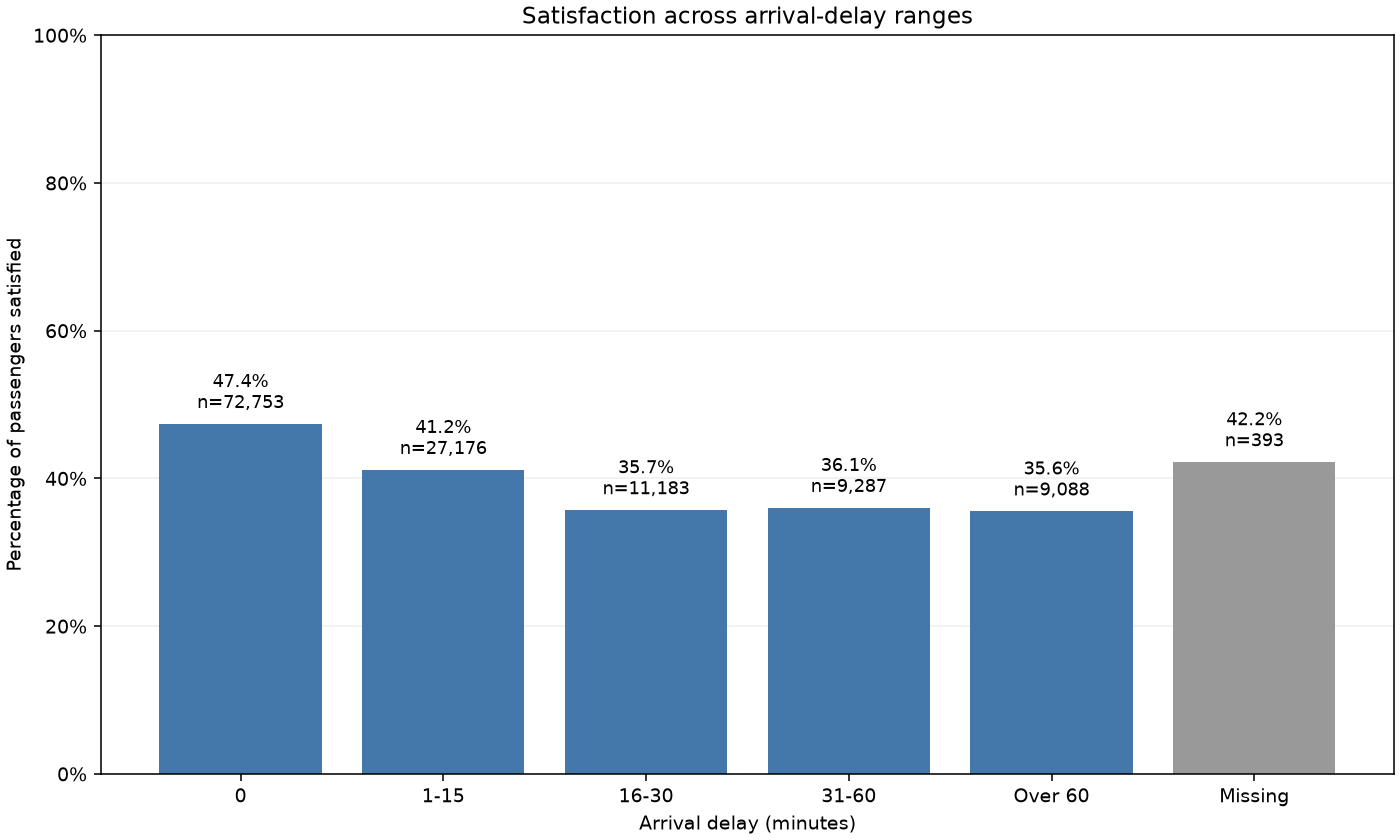

In [4]:
delay_labels = ["0", "1-15", "16-30", "31-60", "Over 60"]
delay_group = pd.cut(df["Arrival Delay in Minutes"],
                     bins=[-0.01, 0, 15, 30, 60, float("inf")],
                     labels=delay_labels)
delay_group = delay_group.cat.add_categories("Missing").fillna("Missing")
delay_summary = (
    df.assign(delay_group=delay_group, is_satisfied=satisfied)
    .groupby("delay_group", observed=False)["is_satisfied"]
    .agg(rate="mean", count="size")
    .reindex(delay_labels + ["Missing"])
)

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
bars = ax.bar(range(len(delay_summary)), delay_summary["rate"] * 100,
              color=["#4477AA"] * 5 + ["#999999"])
ax.bar_label(bars, labels=[f"{r:.1%}\nn={n:,}" for r, n in zip(delay_summary["rate"], delay_summary["count"])],
             padding=5, fontsize=9)
ax.set_xticks(range(len(delay_summary)), delay_summary.index)
ax.set_ylim(0, 100)
ax.set_ylabel("Percentage of passengers satisfied")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlabel("Arrival delay (minutes)")
ax.set_title("Satisfaction across arrival-delay ranges")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.show()


### 3. Age and satisfaction across travel classes

Each panel shows the percentage satisfied within one travel class. All panels use the same 0%-100% scale, and every point has a percentage label. Passenger counts remain in the table below. Groups with fewer than 100 passengers are excluded from the plotted percentages.


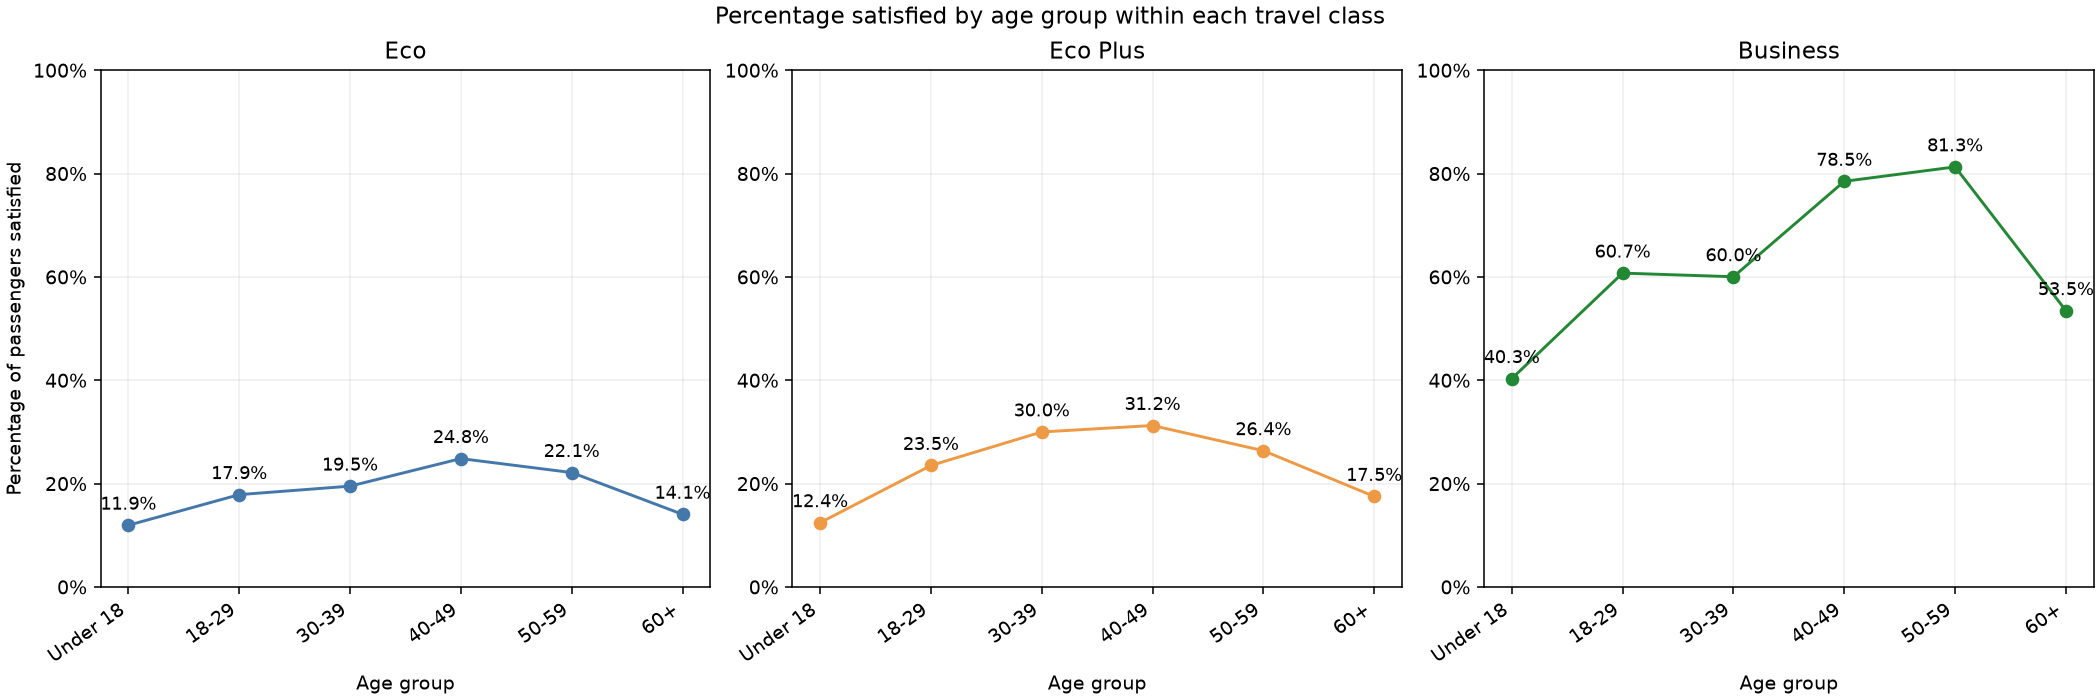

Passenger counts by age group and class:
Class        Eco  Eco Plus  Business
age_group                           
Under 18    7151      1054      1642
18-29      15468      2004     11040
30-39      10362      2057     13285
40-49       9884      1610     18142
50-59       8407      1430     14129
60+         7037      1256      3922


In [5]:
age_labels = ["Under 18", "18-29", "30-39", "40-49", "50-59", "60+"]
age_group = pd.cut(df["Age"], bins=[0, 18, 30, 40, 50, 60, float("inf")],
                   labels=age_labels, right=False)
age_summary = (
    df.assign(age_group=age_group, is_satisfied=satisfied)
    .groupby(["age_group", "Class"], observed=False)["is_satisfied"]
    .agg(rate="mean", count="size")
)
minimum_count = 100
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, layout="constrained")
class_colors = ["#4477AA", "#EE9944", "#228833"]
for ax, travel_class, color in zip(axes, class_order, class_colors):
    group = age_summary.xs(travel_class, level="Class").reindex(age_labels)
    rates = (group["rate"] * 100).where(group["count"].ge(minimum_count))
    ax.plot(range(len(age_labels)), rates, marker="o", color=color)
    for x, rate in enumerate(rates):
        if pd.notna(rate):
            ax.annotate(f"{rate:.1f}%", (x, rate), xytext=(0, 8),
                        textcoords="offset points", ha="center", fontsize=9)
    ax.set_ylim(0, 100)
    ax.set_yticks(range(0, 101, 20))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.tick_params(axis="y", labelleft=True)
    ax.set_xticks(range(len(age_labels)), age_labels, rotation=35, ha="right")
    ax.set_xlabel("Age group")
    ax.set_title(travel_class)
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Percentage of passengers satisfied")
fig.suptitle("Percentage satisfied by age group within each travel class")
plt.show()
print("Passenger counts by age group and class:")
print(age_summary["count"].unstack("Class").reindex(columns=class_order).to_string())
